#Model Training

## LR1. Load Shared Modeling Artifacts

This section restores the shared modeling configuration,
dataset, preprocessing pipeline, and lender-grouped
partition assignments established in Step 15.

The original 12 predictors, held-out test population,
and five cross-validation folds are preserved to ensure
a consistent comparison with Gradient Boosting.

No additional feature selection or data resampling
is performed.

In [1]:
# ============================================================
# LR1. LOAD SHARED MODELING ARTIFACTS
# ============================================================

from google.colab import drive
drive.mount("/content/drive")

import os
import sys
import gc
import time
import json
import joblib
import warnings
import itertools

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import sparse
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning

from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    confusion_matrix
)

from IPython.display import display

sns.set_theme(style="whitegrid")

# ------------------------------------------------------------
# Step 1. Initialize paths
# ------------------------------------------------------------

BASE = "/content/drive/MyDrive/hmda/"
SETUP_DIR = BASE + "rq4_setup/"
OUT = BASE + "rq4_logistic/"
FIGURE_DIR = OUT + "figures/"

os.makedirs(OUT, exist_ok=True)
os.makedirs(FIGURE_DIR, exist_ok=True)

# ------------------------------------------------------------
# Step 2. Load shared configuration
# ------------------------------------------------------------

with open(
    SETUP_DIR + "master_modeling_config.json", "r"
) as f:
    master_config = json.load(f)

configs = master_config["configurations"]
artifacts = master_config["shared_artifacts"]

feature_config = configs["feature_selection"]
evaluation_config = configs["evaluation"]

DATA_PATH = master_config["data_path"]

RANDOM_STATE = master_config["random_state"]
N_SPLITS = feature_config["n_splits"]

TARGET = feature_config["target"]
GROUP = feature_config["group"]

FEATURES = feature_config["features"]
NUMERIC_FEATURES = feature_config["numeric_features"]
CATEGORICAL_FEATURES = feature_config["categorical_features"]

np.random.seed(RANDOM_STATE)

DEFAULT_THRESHOLD = evaluation_config[
    "threshold_selection"
]["default_threshold"]

# ------------------------------------------------------------
# Step 3. Load shared utilities and preprocessor
# ------------------------------------------------------------

sys.path.insert(0, SETUP_DIR)

from evaluation_utils import (
    evaluate_predictions,
    optimize_f1_threshold,
    summarize_cv_results,
    calculate_class_weights
)

lr_preprocessor = joblib.load(
    SETUP_DIR + artifacts["lr_preprocessor"]
)

# ------------------------------------------------------------
# Step 4. Load modeling population
# ------------------------------------------------------------

start = time.perf_counter()

MODEL_COLS = FEATURES + [TARGET, GROUP]

table = pq.read_table(
    DATA_PATH,
    columns=MODEL_COLS
)

for i, field in enumerate(table.schema):

    if pa.types.is_dictionary(field.type):

        table = table.set_column(
            i,
            field.name,
            table.column(i).cast(
                field.type.value_type
            )
        )

model_df = table.to_pandas(
    strings_to_categorical=True
)

del table
gc.collect()

for col in NUMERIC_FEATURES:

    model_df[col] = model_df[col].astype("float32")

for col in CATEGORICAL_FEATURES + [GROUP]:

    model_df[col] = model_df[col].astype("category")

model_df[TARGET] = model_df[TARGET].astype("int8")

# ------------------------------------------------------------
# Step 5. Restore lender-grouped partitions
# ------------------------------------------------------------

lender_split = pd.read_csv(
    SETUP_DIR + artifacts["lender_split"],
    dtype={GROUP: str}
)

assert lender_split[GROUP].is_unique

partition_map = lender_split.set_index(
    GROUP
)["partition"]

partition_assignment = model_df[GROUP].map(
    partition_map
)

assert partition_assignment.notna().all()
assert partition_assignment.isin(["train", "test"]).all()

train_idx = np.flatnonzero(
    partition_assignment.eq("train").to_numpy()
)

test_idx = np.flatnonzero(
    partition_assignment.eq("test").to_numpy()
)

saved_indices = np.load(
    SETUP_DIR + artifacts["train_test_indices"]
)

assert np.array_equal(
    train_idx,
    saved_indices["train_idx"]
), "Training indices differ from Step 15."

assert np.array_equal(
    test_idx,
    saved_indices["test_idx"]
), "Test indices differ from Step 15."

saved_indices.close()

# ------------------------------------------------------------
# Step 6. Restore cross-validation folds
# ------------------------------------------------------------

cv_lender_split = pd.read_csv(
    SETUP_DIR + artifacts["cv_fold_assignment"],
    dtype={GROUP: str}
)

assert cv_lender_split[GROUP].is_unique

cv_fold_map = cv_lender_split.set_index(
    GROUP
)["validation_fold"]

groups_train = (
    model_df[GROUP]
    .iloc[train_idx]
    .reset_index(drop=True)
)

groups_test = (
    model_df[GROUP]
    .iloc[test_idx]
    .reset_index(drop=True)
)

fold_assignment = groups_train.map(cv_fold_map)

assert fold_assignment.notna().all()

fold_assignment = fold_assignment.to_numpy(
    dtype=np.int8
)

saved_folds = np.load(
    SETUP_DIR + artifacts["cv_fold_array"]
)

assert np.array_equal(
    fold_assignment,
    saved_folds
), "CV assignments differ from Step 15."

# ------------------------------------------------------------
# Step 7. Build modeling partitions
# ------------------------------------------------------------

X_train = (
    model_df.iloc[train_idx][FEATURES]
    .reset_index(drop=True)
)

X_test = (
    model_df.iloc[test_idx][FEATURES]
    .reset_index(drop=True)
)

y_train = model_df[TARGET].to_numpy()[train_idx]
y_test = model_df[TARGET].to_numpy()[test_idx]

train_lenders = set(groups_train)
test_lenders = set(groups_test)

# ------------------------------------------------------------
# Step 8. Validate partition integrity
# ------------------------------------------------------------

population = master_config["population"]

assert len(FEATURES) == 12

assert len(model_df) == population[
    "total_applications"
]

assert len(X_train) == population[
    "training_applications"
]

assert len(X_test) == population[
    "test_applications"
]

assert len(train_lenders.intersection(test_lenders)) == 0

assert set(np.unique(y_train)) == {0, 1}
assert set(np.unique(y_test)) == {0, 1}

assert set(np.unique(fold_assignment)) == set(
    range(1, N_SPLITS + 1)
)

for fold in range(1, N_SPLITS + 1):

    fit_lenders = set(
        groups_train[fold_assignment != fold]
    )

    val_lenders = set(
        groups_train[fold_assignment == fold]
    )

    assert not fit_lenders.intersection(val_lenders)

# ------------------------------------------------------------
# Step 9. Display partition and class summaries
# ------------------------------------------------------------

partition_summary = pd.DataFrame([
    {
        "partition": "Training",
        "applications": len(y_train),
        "lenders": len(train_lenders),
        "originated": int((y_train == 0).sum()),
        "denied": int((y_train == 1).sum()),
        "denial_rate_pct": y_train.mean() * 100
    },
    {
        "partition": "Test",
        "applications": len(y_test),
        "lenders": len(test_lenders),
        "originated": int((y_test == 0).sum()),
        "denied": int((y_test == 1).sum()),
        "denial_rate_pct": y_test.mean() * 100
    }
])

class_weights = calculate_class_weights(y_train)

class_weight_summary = pd.DataFrame({
    "class": [0, 1],
    "label": ["Originated", "Denied"],
    "unweighted": [1.0, 1.0],
    "balanced": [class_weights[0], class_weights[1]]
})

display(partition_summary.round(4))
display(class_weight_summary.round(4))

partition_summary.to_csv(
    OUT + "lr_partition_summary.csv",
    index=False
)

class_weight_summary.to_csv(
    OUT + "lr_class_weight_summary.csv",
    index=False
)

# ------------------------------------------------------------
# Step 10. Release unnecessary data
# ------------------------------------------------------------

del model_df
del partition_assignment
del saved_folds

gc.collect()

print("Original predictors:", len(FEATURES))
print("Cross-validation folds:", N_SPLITS)
print("Partition integrity: PASS")

print(
    f"Loading runtime: "
    f"{time.perf_counter() - start:.2f}s"
)

print("\nLR1 completed successfully.")

Mounted at /content/drive


,partition,applications,lenders,originated,denied,denial_rate_pct
0,Training,6308273,3927,4698384,1609889,25.5203
1,Test,1992274,982,1498701,493573,24.7744


,class,label,unweighted,balanced
0,0,Originated,1.0,0.6713
1,1,Denied,1.0,1.9592


Original predictors: 12
Cross-validation folds: 5
Partition integrity: PASS
Loading runtime: 32.19s

LR1 completed successfully.


## LR1.5. Baseline Logistic Regression

A standard Logistic Regression model with L2 regularization,
C = 1.0, and no class weighting is established as the
baseline before hyperparameter optimization.

The baseline follows the shared five-fold lender-grouped
cross-validation strategy and preprocessing configuration.

Out-of-fold predictions are used to determine an optimized
classification threshold based on F1-score.

The final baseline model is evaluated on the held-out
test partition at both default and optimized thresholds
to quantify the incremental benefits of subsequent
hyperparameter tuning.

Baseline Logistic Regression:
{
    "penalty": "l2",
    "C": 1.0,
    "class_weight": null,
    "solver": "lbfgs",
    "max_iter": 500,
    "tol": 0.0001,
    "random_state": 42
}

BASELINE CV FOLD 1/5
AUC=0.778628 | AP=0.603658 | F1=0.496657 | Time=19.53s | Converged=True

BASELINE CV FOLD 2/5
AUC=0.789126 | AP=0.690344 | F1=0.512010 | Time=25.65s | Converged=True

BASELINE CV FOLD 3/5
AUC=0.812404 | AP=0.679911 | F1=0.554668 | Time=20.42s | Converged=True

BASELINE CV FOLD 4/5
AUC=0.815049 | AP=0.662769 | F1=0.535913 | Time=16.05s | Converged=True

BASELINE CV FOLD 5/5
AUC=0.848484 | AP=0.734635 | F1=0.584186 | Time=24.52s | Converged=True

Baseline CV fold results:


,fold,roc_auc,average_precision,accuracy,precision,recall,f1,brier_score,converged
0,1,0.778628,0.603658,0.825238,0.685643,0.389341,0.496657,0.132438,True
1,2,0.789126,0.690344,0.783508,0.824953,0.371197,0.512010,0.158603,True
2,3,0.812404,0.679911,0.832451,0.767617,0.434211,0.554668,0.125787,True
3,4,0.815049,0.662769,0.825938,0.735102,0.421657,0.535913,0.127893,True
4,5,0.848484,0.734635,0.824745,0.812456,0.456053,0.584186,0.126175,True



Baseline CV summary:


,metric,mean,std
0,average_precision,0.674263,0.047572
1,roc_auc,0.808738,0.027038
2,accuracy,0.818376,0.019740
3,precision,0.765154,0.057106
4,recall,0.414492,0.034185
5,f1,0.536687,0.034610
6,specificity,0.957289,0.006478
7,brier_score,0.134179,0.013907
8,training_time_sec,21.235074,3.895304
9,inference_time_sec,0.035639,0.006727



Baseline threshold optimization:


,model,default_threshold,optimal_threshold,optimization_metric,optimization_data,oof_f1,oof_precision,oof_recall
0,Baseline Logistic Regression,0.5,0.322416,F1-score,Out-of-fold predictions,0.582154,0.604532,0.561374


,threshold,average_precision,roc_auc,accuracy,precision,recall,f1,specificity,brier_score,true_negative,false_positive,false_negative,true_positive,model,threshold_type
0,0.500000,0.673204,0.807066,0.818376,0.767521,0.413590,0.537526,0.957075,0.134179,4496706,201678,944055,665834,Baseline Logistic Regression,Default
1,0.322416,0.673204,0.807066,0.794342,0.604532,0.561374,0.582154,0.874168,0.134179,4107177,591207,706139,903750,Baseline Logistic Regression,Optimized



Fitting final baseline model...
Preprocessing time: 15.23s
Training time: 26.62s
Converged: True

Baseline held-out test performance:


threshold_type,Default,Optimized,Difference
threshold,5.000000e-01,3.224160e-01,-0.177584
roc_auc,8.286680e-01,8.286680e-01,0.000000
average_precision,6.839930e-01,6.839930e-01,0.000000
accuracy,8.230830e-01,8.040140e-01,-0.019069
precision,7.266680e-01,6.033970e-01,-0.123271
recall,4.582540e-01,6.095880e-01,0.151333
f1,5.620600e-01,6.064760e-01,0.044416
specificity,9.432330e-01,8.680450e-01,-0.075188
brier_score,1.274540e-01,1.274540e-01,0.000000
true_negative,1.413624e+06,1.300940e+06,-112684.000000


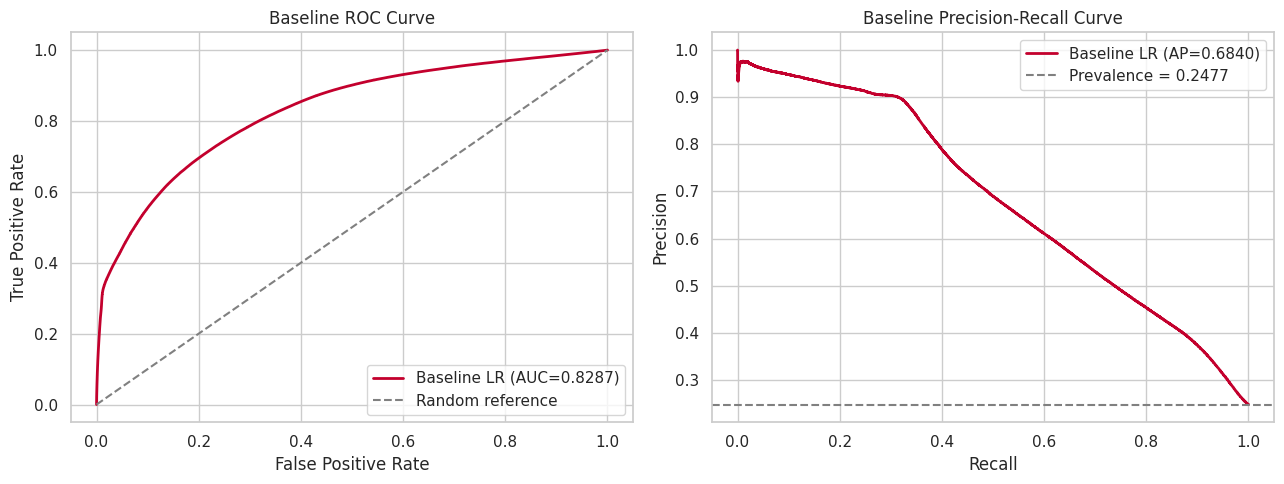


LR1.5 — BASELINE LOGISTIC REGRESSION COMPLETED
Mean CV ROC-AUC: 0.808738
Mean CV Average Precision: 0.674263
Test ROC-AUC: 0.828668
Test Average Precision: 0.683993
Default Test F1: 0.562060
Optimized Test F1: 0.606476
Optimal threshold: 0.322416
Total runtime: 4.19 minutes
Output directory: /content/drive/MyDrive/hmda/rq4_logistic/baseline

Ready for LR2 — Hyperparameter Tuning.


In [7]:
# ============================================================
# LR1.5. BASELINE LOGISTIC REGRESSION
# ============================================================

# ------------------------------------------------------------
# Step 1. Initialize baseline configuration
# ------------------------------------------------------------

BASELINE_DIR = os.path.join(OUT, "baseline")

os.makedirs(BASELINE_DIR, exist_ok=True)

BASELINE_LR_PARAMS = {
    "penalty": "l2",
    "C": 1.0,
    "class_weight": None,
    "solver": "lbfgs",
    "max_iter": 500,
    "tol": 1e-4,
    "random_state": RANDOM_STATE
}

baseline_start = time.perf_counter()

baseline_cv_results = []

baseline_oof_prob = np.full(
    len(y_train),
    np.nan,
    dtype=np.float64
)

print("Baseline Logistic Regression:")

print(
    json.dumps(
        BASELINE_LR_PARAMS,
        indent=4
    )
)

# ------------------------------------------------------------
# Step 2. Lender-grouped cross-validation
# ------------------------------------------------------------

for fold in range(1, N_SPLITS + 1):

    print("\n" + "=" * 65)
    print(f"BASELINE CV FOLD {fold}/{N_SPLITS}")
    print("=" * 65)

    fit_idx = np.flatnonzero(
        fold_assignment != fold
    )

    val_idx = np.flatnonzero(
        fold_assignment == fold
    )

    X_fit = X_train.iloc[fit_idx]
    X_val = X_train.iloc[val_idx]

    y_fit = y_train[fit_idx]
    y_val = y_train[val_idx]

    # Fit preprocessing within the training fold

    preprocessing_start = time.perf_counter()

    baseline_preprocessor = clone(
        lr_preprocessor
    )

    X_fit_transformed = sparse.csr_matrix(
        baseline_preprocessor.fit_transform(X_fit),
        dtype=np.float64
    )

    X_val_transformed = sparse.csr_matrix(
        baseline_preprocessor.transform(X_val),
        dtype=np.float64
    )

    preprocessing_time = (
        time.perf_counter() - preprocessing_start
    )

    del X_fit, X_val
    gc.collect()

    # Train baseline model

    baseline_model = LogisticRegression(
        **BASELINE_LR_PARAMS
    )

    fit_start = time.perf_counter()

    with warnings.catch_warnings(record=True) as caught:

        warnings.simplefilter(
            "always",
            ConvergenceWarning
        )

        baseline_model.fit(
            X_fit_transformed,
            y_fit
        )

    training_time = (
        time.perf_counter() - fit_start
    )

    converged = not any(
        issubclass(w.category, ConvergenceWarning)
        for w in caught
    )

    # Predict validation probabilities

    inference_start = time.perf_counter()

    y_val_prob = baseline_model.predict_proba(
        X_val_transformed
    )[:, 1]

    inference_time = (
        time.perf_counter() - inference_start
    )

    baseline_oof_prob[val_idx] = y_val_prob

    # Evaluate validation performance

    metrics = evaluate_predictions(
        y_val,
        y_val_prob,
        threshold=DEFAULT_THRESHOLD
    )

    metrics.update({
        "model": "Baseline Logistic Regression",
        "fold": fold,
        "C": 1.0,
        "weight_strategy": "Unweighted",
        "training_observations": len(y_fit),
        "validation_observations": len(y_val),
        "preprocessing_time_sec": preprocessing_time,
        "training_time_sec": training_time,
        "inference_time_sec": inference_time,
        "n_iterations": int(
            baseline_model.n_iter_.max()
        ),
        "converged": converged
    })

    baseline_cv_results.append(metrics)

    print(
        f"AUC={metrics['roc_auc']:.6f} | "
        f"AP={metrics['average_precision']:.6f} | "
        f"F1={metrics['f1']:.6f} | "
        f"Time={training_time:.2f}s | "
        f"Converged={converged}"
    )

    # Release fold-specific objects

    del X_fit_transformed
    del X_val_transformed
    del baseline_preprocessor
    del baseline_model
    del y_val_prob
    del y_fit, y_val

    gc.collect()

# ------------------------------------------------------------
# Step 3. Summarize cross-validation performance
# ------------------------------------------------------------

baseline_cv_df = pd.DataFrame(
    baseline_cv_results
)

assert baseline_cv_df["converged"].all()

assert np.isfinite(
    baseline_oof_prob
).all()

baseline_cv_summary = summarize_cv_results(
    baseline_cv_df
)

print("\nBaseline CV fold results:")

display(
    baseline_cv_df[
        [
            "fold",
            "roc_auc",
            "average_precision",
            "accuracy",
            "precision",
            "recall",
            "f1",
            "brier_score",
            "converged"
        ]
    ].round(6)
)

print("\nBaseline CV summary:")

display(
    baseline_cv_summary.round(6)
)

baseline_cv_df.to_csv(
    os.path.join(
        BASELINE_DIR,
        "baseline_cv_fold_results.csv"
    ),
    index=False
)

baseline_cv_summary.to_csv(
    os.path.join(
        BASELINE_DIR,
        "baseline_cv_summary.csv"
    ),
    index=False
)

# ------------------------------------------------------------
# Step 4. Optimize classification threshold
# ------------------------------------------------------------

baseline_threshold_result = optimize_f1_threshold(
    y_train,
    baseline_oof_prob
)

BASELINE_OPTIMAL_THRESHOLD = float(
    baseline_threshold_result["optimal_threshold"]
)

baseline_threshold_config = {
    "model": "Baseline Logistic Regression",
    "default_threshold": float(DEFAULT_THRESHOLD),
    "optimal_threshold": BASELINE_OPTIMAL_THRESHOLD,
    "optimization_metric": "F1-score",
    "optimization_data": "Out-of-fold predictions",
    "oof_f1": float(
        baseline_threshold_result["optimal_f1"]
    ),
    "oof_precision": float(
        baseline_threshold_result["precision"]
    ),
    "oof_recall": float(
        baseline_threshold_result["recall"]
    )
}

with open(
    os.path.join(
        BASELINE_DIR,
        "baseline_threshold.json"
    ),
    "w"
) as f:

    json.dump(
        baseline_threshold_config,
        f,
        indent=4
    )

print("\nBaseline threshold optimization:")

display(
    pd.DataFrame([
        baseline_threshold_config
    ]).round(6)
)

# ------------------------------------------------------------
# Step 5. Compare OOF threshold performance
# ------------------------------------------------------------

baseline_oof_results = []

for threshold_type, threshold in [
    ("Default", DEFAULT_THRESHOLD),
    ("Optimized", BASELINE_OPTIMAL_THRESHOLD)
]:

    metrics = evaluate_predictions(
        y_train,
        baseline_oof_prob,
        threshold=threshold
    )

    metrics["model"] = (
        "Baseline Logistic Regression"
    )

    metrics["threshold_type"] = threshold_type

    baseline_oof_results.append(metrics)

baseline_oof_metrics = pd.DataFrame(
    baseline_oof_results
)

display(
    baseline_oof_metrics.round(6)
)

baseline_oof_metrics.to_csv(
    os.path.join(
        BASELINE_DIR,
        "baseline_oof_metrics.csv"
    ),
    index=False
)

# ------------------------------------------------------------
# Step 6. Fit baseline on full training set
# ------------------------------------------------------------

print("\nFitting final baseline model...")

baseline_final_preprocessor = clone(
    lr_preprocessor
)

preprocessing_start = time.perf_counter()

X_train_baseline = sparse.csr_matrix(
    baseline_final_preprocessor.fit_transform(
        X_train
    ),
    dtype=np.float64
)

baseline_preprocessing_time = (
    time.perf_counter() - preprocessing_start
)

baseline_final_model = LogisticRegression(
    **BASELINE_LR_PARAMS
)

fit_start = time.perf_counter()

with warnings.catch_warnings(record=True) as caught:

    warnings.simplefilter(
        "always",
        ConvergenceWarning
    )

    baseline_final_model.fit(
        X_train_baseline,
        y_train
    )

baseline_training_time = (
    time.perf_counter() - fit_start
)

baseline_converged = not any(
    issubclass(w.category, ConvergenceWarning)
    for w in caught
)

assert baseline_converged

baseline_final_pipeline = Pipeline([
    ("preprocessor", baseline_final_preprocessor),
    ("classifier", baseline_final_model)
])

del X_train_baseline

gc.collect()

print(
    f"Preprocessing time: "
    f"{baseline_preprocessing_time:.2f}s"
)

print(
    f"Training time: "
    f"{baseline_training_time:.2f}s"
)

print("Converged:", baseline_converged)

# ------------------------------------------------------------
# Step 7. Predict held-out test probabilities
# ------------------------------------------------------------

inference_start = time.perf_counter()

baseline_test_prob = (
    baseline_final_pipeline.predict_proba(
        X_test
    )[:, 1]
)

baseline_inference_time = (
    time.perf_counter() - inference_start
)

assert len(baseline_test_prob) == len(y_test)

assert np.isfinite(
    baseline_test_prob
).all()

# ------------------------------------------------------------
# Step 8. Evaluate held-out test performance
# ------------------------------------------------------------

baseline_test_results = []

for threshold_type, threshold in [
    ("Default", DEFAULT_THRESHOLD),
    ("Optimized", BASELINE_OPTIMAL_THRESHOLD)
]:

    metrics = evaluate_predictions(
        y_test,
        baseline_test_prob,
        threshold=threshold
    )

    metrics.update({
        "model": "Baseline Logistic Regression",
        "config_id": "LR_05",
        "threshold_type": threshold_type,
        "test_observations": len(y_test),

        "preprocessing_time_sec": (
            baseline_preprocessing_time
        ),

        "training_time_sec": (
            baseline_training_time
        ),

        "total_fit_time_sec": (
            baseline_preprocessing_time
            + baseline_training_time
        ),

        "inference_time_sec": (
            baseline_inference_time
        ),

        "converged": baseline_converged
    })

    baseline_test_results.append(metrics)

baseline_test_metrics = pd.DataFrame(
    baseline_test_results
)

baseline_test_metrics.to_csv(
    os.path.join(
        BASELINE_DIR,
        "baseline_test_metrics.csv"
    ),
    index=False
)

# ------------------------------------------------------------
# Step 9. Display test threshold comparison
# ------------------------------------------------------------

BASELINE_METRICS = [
    "threshold",
    "roc_auc",
    "average_precision",
    "accuracy",
    "precision",
    "recall",
    "f1",
    "specificity",
    "brier_score",
    "true_negative",
    "false_positive",
    "false_negative",
    "true_positive"
]

baseline_comparison = (
    baseline_test_metrics
    .set_index("threshold_type")[BASELINE_METRICS]
    .T
)

baseline_comparison["Difference"] = (
    baseline_comparison["Optimized"]
    - baseline_comparison["Default"]
)

print("\nBaseline held-out test performance:")

display(
    baseline_comparison.round(6)
)

baseline_comparison.to_csv(
    os.path.join(
        BASELINE_DIR,
        "baseline_threshold_comparison.csv"
    )
)

# ------------------------------------------------------------
# Step 10. Plot baseline ROC and PR curves
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5)
)

# ROC curve

fpr, tpr, _ = roc_curve(
    y_test,
    baseline_test_prob
)

baseline_auc = baseline_test_metrics.iloc[0][
    "roc_auc"
]

axes[0].plot(
    fpr,
    tpr,
    color="#C3002D",
    linewidth=2,
    label=f"Baseline LR (AUC={baseline_auc:.4f})"
)

axes[0].plot(
    [0, 1],
    [0, 1],
    color="gray",
    linestyle="--",
    label="Random reference"
)

axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("Baseline ROC Curve")
axes[0].legend(loc="lower right")

# Precision-Recall curve

precision, recall, _ = precision_recall_curve(
    y_test,
    baseline_test_prob
)

baseline_ap = baseline_test_metrics.iloc[0][
    "average_precision"
]

axes[1].plot(
    recall,
    precision,
    color="#C3002D",
    linewidth=2,
    label=f"Baseline LR (AP={baseline_ap:.4f})"
)

axes[1].axhline(
    y_test.mean(),
    color="gray",
    linestyle="--",
    label=f"Prevalence = {y_test.mean():.4f}"
)

axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Baseline Precision-Recall Curve")
axes[1].legend(loc="upper right")

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "LR1_5_baseline_roc_pr_curves.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# Step 11. Export baseline predictions
# ------------------------------------------------------------

baseline_oof_export = pd.DataFrame({
    "row_idx": train_idx,
    GROUP: groups_train.astype(str),
    "validation_fold": fold_assignment,
    "y_true": y_train,
    "y_prob": baseline_oof_prob
})

baseline_test_export = pd.DataFrame({
    "row_idx": test_idx,
    GROUP: groups_test.astype(str),
    "y_true": y_test,
    "y_prob": baseline_test_prob,

    "y_pred_default": (
        baseline_test_prob >= DEFAULT_THRESHOLD
    ).astype(np.int8),

    "y_pred_optimized": (
        baseline_test_prob >= BASELINE_OPTIMAL_THRESHOLD
    ).astype(np.int8)
})

assert baseline_oof_export["row_idx"].is_unique
assert baseline_test_export["row_idx"].is_unique

assert len(baseline_oof_export) == len(y_train)
assert len(baseline_test_export) == len(y_test)

baseline_oof_export.to_parquet(
    os.path.join(
        BASELINE_DIR,
        "baseline_oof_predictions.parquet"
    ),
    index=False
)

baseline_test_export.to_parquet(
    os.path.join(
        BASELINE_DIR,
        "baseline_test_predictions.parquet"
    ),
    index=False
)

# ------------------------------------------------------------
# Step 12. Export final model and configuration
# ------------------------------------------------------------

joblib.dump(
    baseline_final_pipeline,
    os.path.join(
        BASELINE_DIR,
        "baseline_lr_final_pipeline.joblib"
    )
)

baseline_config = {
    "model": "Baseline Logistic Regression",
    "config_id": "LR_05",
    "parameters": BASELINE_LR_PARAMS,
    "primary_metric": "roc_auc",
    "secondary_metric": "average_precision",
    "cv_folds": N_SPLITS,
    "default_threshold": float(DEFAULT_THRESHOLD),
    "optimal_threshold": BASELINE_OPTIMAL_THRESHOLD,
    "training_observations": len(y_train),
    "test_observations": len(y_test),
    "converged": bool(baseline_converged)
}

with open(
    os.path.join(
        BASELINE_DIR,
        "baseline_model_config.json"
    ),
    "w"
) as f:

    json.dump(
        baseline_config,
        f,
        indent=4
    )

# ------------------------------------------------------------
# Step 13. Display final baseline summary
# ------------------------------------------------------------

baseline_runtime = (
    time.perf_counter() - baseline_start
)

print("\n" + "=" * 65)

print("LR1.5 — BASELINE LOGISTIC REGRESSION COMPLETED")

print("=" * 65)

print(
    f"Mean CV ROC-AUC: "
    f"{baseline_cv_df['roc_auc'].mean():.6f}"
)

print(
    f"Mean CV Average Precision: "
    f"{baseline_cv_df['average_precision'].mean():.6f}"
)

print(
    f"Test ROC-AUC: "
    f"{baseline_auc:.6f}"
)

print(
    f"Test Average Precision: "
    f"{baseline_ap:.6f}"
)

print(
    f"Default Test F1: "
    f"{baseline_test_metrics.iloc[0]['f1']:.6f}"
)

print(
    f"Optimized Test F1: "
    f"{baseline_test_metrics.iloc[1]['f1']:.6f}"
)

print(
    f"Optimal threshold: "
    f"{BASELINE_OPTIMAL_THRESHOLD:.6f}"
)

print(
    f"Total runtime: "
    f"{baseline_runtime / 60:.2f} minutes"
)

print("Output directory:", BASELINE_DIR)

del baseline_oof_export
del baseline_test_export

gc.collect()

print("\nReady for LR2 — Hyperparameter Tuning.")

## LR2. Cross-Validation and Hyperparameter Tuning

L2-regularized Logistic Regression is evaluated using
five-fold lender-grouped cross-validation.

The hyperparameter search examines four regularization
strengths and two class imbalance handling strategies:

- Regularization: L2
- C: 0.01, 0.1, 1.0, 10.0
- Class weighting: Unweighted and Balanced
- Solver: LBFGS

Preprocessing is fitted independently within each
training fold and reused across candidate configurations
to reduce computational overhead and prevent data leakage.

Mean cross-validation ROC-AUC is used as the primary
model selection criterion, consistent with previous
mortgage denial prediction studies.

Average Precision is retained as a secondary metric
to assess predictive performance for the denied class.

Among configurations that converge across all folds,
the optimal configuration is selected based on:

1. Highest mean CV ROC-AUC.
2. Highest mean CV Average Precision.
3. Lowest standard deviation of CV ROC-AUC.

Out-of-fold predictions from the selected configuration
are retained for subsequent F1-based classification
threshold optimization.

,config_id,C,class_weight,weight_strategy
0,LR_01,0.01,None,Unweighted
1,LR_02,0.01,balanced,Balanced
2,LR_03,0.10,None,Unweighted
3,LR_04,0.10,balanced,Balanced
4,LR_05,1.00,None,Unweighted
5,LR_06,1.00,balanced,Balanced
6,LR_07,10.00,None,Unweighted
7,LR_08,10.00,balanced,Balanced


Primary metric: roc_auc
Secondary metric: average_precision
Configurations: 8
Cross-validation folds: 5
Total CV fits: 40

FOLD 1/5
Training observations: 5,046,618
Validation observations: 1,261,655
Training denial rate: 26.3641%
Validation denial rate: 22.1451%
Balanced class weights: {0: 0.6790163622096571, 1: 1.896520390170869}
Encoded features: 88
Preprocessing time: 16.06s
LR_01 | C=0.01 | Unweighted | AUC=0.77853 | AP=0.60342 | F1=0.49627 | Time=19.1s | Converged=True
LR_02 | C=0.01 | Balanced | AUC=0.78139 | AP=0.60508 | F1=0.50740 | Time=19.7s | Converged=True
LR_03 | C=0.1 | Unweighted | AUC=0.77848 | AP=0.60328 | F1=0.49628 | Time=21.8s | Converged=True
LR_04 | C=0.1 | Balanced | AUC=0.78124 | AP=0.60490 | F1=0.50707 | Time=23.0s | Converged=True
LR_05 | C=1.0 | Unweighted | AUC=0.77863 | AP=0.60366 | F1=0.49666 | Time=18.4s | Converged=True
LR_06 | C=1.0 | Balanced | AUC=0.78128 | AP=0.60486 | F1=0.50722 | Time=23.8s | Converged=True
LR_07 | C=10.0 | Unweighted | AUC=0.7786

,rank,config_id,C,weight_strategy,completed_folds,mean_cv_auc,std_cv_auc,mean_cv_ap,std_cv_ap,mean_cv_f1,...,mean_cv_precision,mean_cv_recall,mean_cv_accuracy,mean_cv_specificity,mean_cv_brier,mean_training_time_sec,mean_inference_time_sec,mean_iterations,converged_folds,eligible
0,1,LR_02,0.01,Balanced,5,0.813145,0.026168,0.676050,0.048601,0.574522,...,0.509171,0.667029,0.749552,0.779549,0.164041,20.983484,0.037351,59.6,5,True
1,2,LR_04,0.10,Balanced,5,0.812842,0.026199,0.675752,0.048505,0.574156,...,0.509123,0.666235,0.749467,0.779737,0.164093,21.298450,0.036882,60.0,5,True
2,3,LR_06,1.00,Balanced,5,0.812796,0.026009,0.675689,0.048310,0.574033,...,0.509028,0.666053,0.749402,0.779718,0.164091,22.631200,0.031301,63.4,5,True
3,4,LR_08,10.00,Balanced,5,0.812765,0.026029,0.675676,0.048297,0.574002,...,0.508974,0.666057,0.749371,0.779675,0.164098,22.186923,0.031215,62.2,5,True
4,5,LR_01,0.01,Unweighted,5,0.808814,0.027510,0.674402,0.047944,0.536896,...,0.765103,0.414780,0.818425,0.957253,0.134146,19.281710,0.042425,59.6,5,True
5,6,LR_05,1.00,Unweighted,5,0.808738,0.027038,0.674263,0.047572,0.536687,...,0.765154,0.414492,0.818376,0.957289,0.134179,19.050067,0.035095,60.8,5,True
6,7,LR_07,10.00,Unweighted,5,0.808720,0.027478,0.674354,0.047792,0.536995,...,0.764892,0.414943,0.818415,0.957182,0.134171,19.090288,0.031848,58.4,5,True
7,8,LR_03,0.10,Unweighted,5,0.808485,0.027222,0.674065,0.047656,0.536661,...,0.764886,0.414547,0.818334,0.957219,0.134237,19.827671,0.033901,61.0,5,True



Best configuration:
{
    "config_id": "LR_02",
    "C": 0.01,
    "class_weight": "balanced",
    "weight_strategy": "Balanced",
    "penalty": "l2",
    "solver": "lbfgs",
    "max_iter": 500,
    "tol": 0.0001,
    "random_state": 42,
    "primary_metric": "roc_auc",
    "secondary_metric": "average_precision",
    "mean_cv_auc": 0.8131449622731282,
    "std_cv_auc": 0.0261679826429282,
    "mean_cv_ap": 0.676050181798485,
    "std_cv_ap": 0.04860069144848785,
    "mean_cv_f1": 0.574521511236561,
    "mean_cv_brier": 0.16404113188923725,
    "converged_folds": 5
}

Selected configuration across CV folds:


,fold,roc_auc,average_precision,accuracy,precision,recall,f1,brier_score,converged
1,1,0.781395,0.605081,0.711640,0.408074,0.670620,0.507396,0.179361,True
9,2,0.801335,0.696323,0.741825,0.575399,0.596004,0.585520,0.167322,True
17,3,0.812480,0.677426,0.763837,0.506524,0.668853,0.576479,0.159211,True
25,4,0.817748,0.663413,0.755317,0.490391,0.678312,0.569243,0.162160,True
33,5,0.852767,0.738009,0.775143,0.565467,0.721354,0.633968,0.152151,True



Cross-validation performance summary:


,metric,mean,std
0,average_precision,0.676050,0.048601
1,roc_auc,0.813145,0.026168
2,accuracy,0.749552,0.024440
3,precision,0.509171,0.067334
4,recall,0.667029,0.045109
5,f1,0.574522,0.045256
6,specificity,0.779549,0.032840
7,brier_score,0.164041,0.010170
8,training_time_sec,20.983484,0.939584
9,inference_time_sec,0.037351,0.011803



Baseline vs. optimized configuration:


,metric,baseline,optimized,difference
0,mean_cv_auc,0.808738,0.813145,0.004407
1,mean_cv_ap,0.674263,0.676050,0.001787
2,mean_cv_f1,0.536687,0.574522,0.037835
3,mean_cv_precision,0.765154,0.509171,-0.255983
4,mean_cv_recall,0.414492,0.667029,0.252537
5,mean_cv_brier,0.134179,0.164041,0.029862
6,mean_training_time_sec,19.050067,20.983484,1.933418


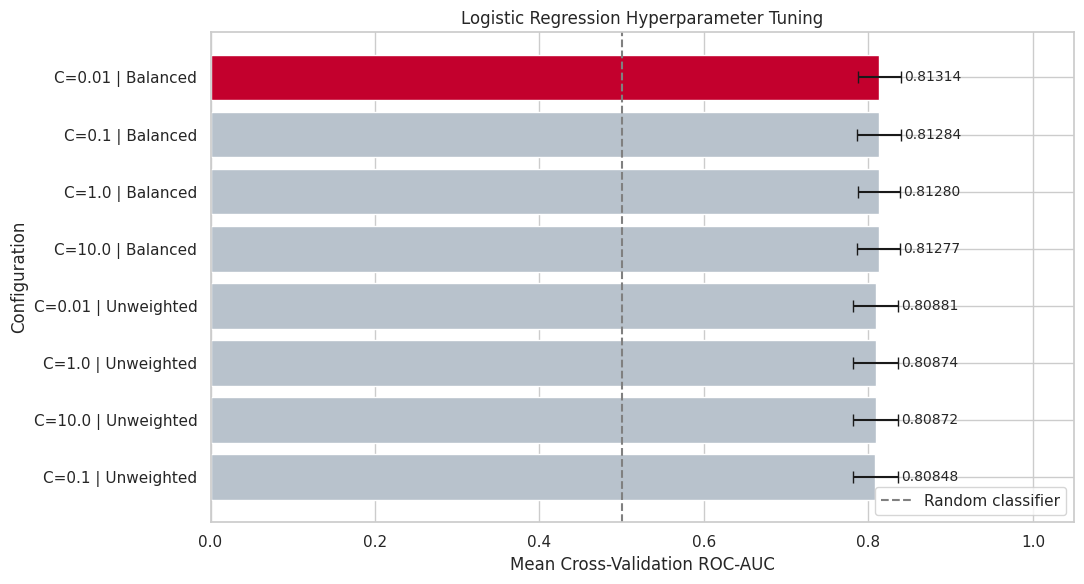

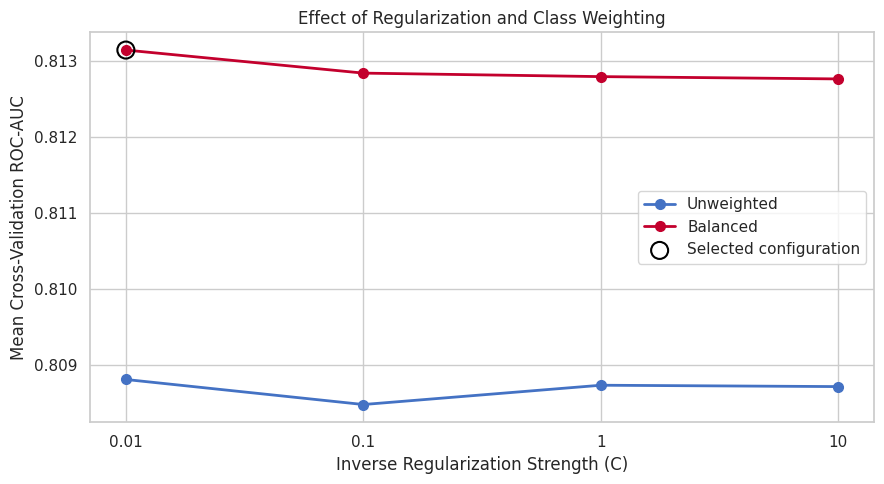

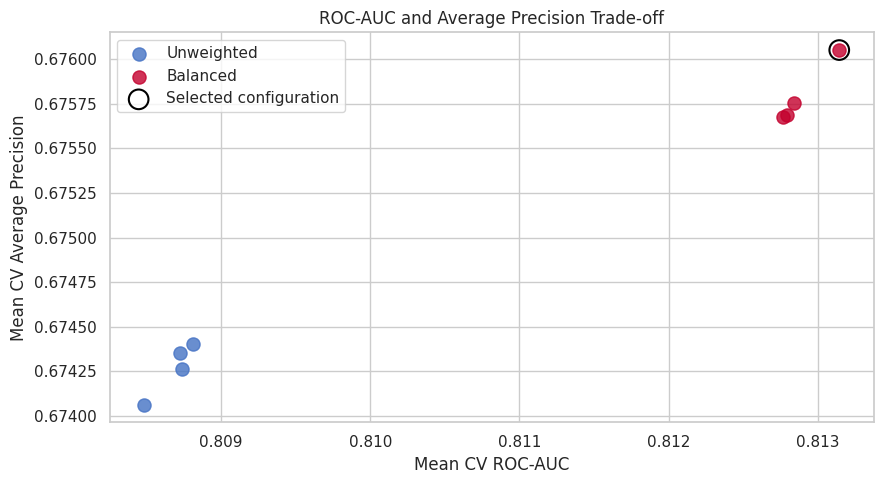


LR2 — HYPERPARAMETER TUNING COMPLETED
Primary selection metric: ROC-AUC
Selected configuration: LR_02
Selected C: 0.01
Selected weighting: Balanced
Mean CV ROC-AUC: 0.813145
Std CV ROC-AUC: 0.026168
Mean CV Average Precision: 0.676050
Mean CV F1: 0.574522
Converged folds: 5/5
ROC-AUC improvement over baseline: +0.004407
Total CV runtime: 15.70 minutes

OOF prediction coverage: PASS
Ready for LR3 — Final Model Training and Evaluation.


In [3]:
# ============================================================
# LR2. CROSS-VALIDATION AND HYPERPARAMETER TUNING
# ============================================================

# ------------------------------------------------------------
# Step 1. Define hyperparameter search space
# ------------------------------------------------------------

LR_PARAM_GRID = {
    "C": [0.01, 0.1, 1.0, 10.0],
    "class_weight": [None, "balanced"]
}

LR_SOLVER = "lbfgs"
LR_PENALTY = "l2"
LR_MAX_ITER = 500
LR_TOL = 1e-4

LR_PRIMARY_METRIC = "roc_auc"
LR_SECONDARY_METRIC = "average_precision"

LR_CONFIGS = []

for i, (c, weight) in enumerate(
    itertools.product(
        LR_PARAM_GRID["C"],
        LR_PARAM_GRID["class_weight"]
    ),
    start=1
):

    LR_CONFIGS.append({
        "config_id": f"LR_{i:02d}",
        "C": c,
        "class_weight": weight,
        "weight_strategy": (
            "Unweighted"
            if weight is None
            else "Balanced"
        )
    })

display(pd.DataFrame(LR_CONFIGS))

print("Primary metric:", LR_PRIMARY_METRIC)
print("Secondary metric:", LR_SECONDARY_METRIC)
print("Configurations:", len(LR_CONFIGS))
print("Cross-validation folds:", N_SPLITS)
print("Total CV fits:", len(LR_CONFIGS) * N_SPLITS)

# ------------------------------------------------------------
# Step 2. Initialize CV results and OOF storage
# ------------------------------------------------------------

cv_results = []

oof_predictions = {
    config["config_id"]: np.full(
        len(y_train),
        np.nan,
        dtype=np.float64
    )
    for config in LR_CONFIGS
}

cv_start = time.perf_counter()

# ------------------------------------------------------------
# Step 3. Define reusable model constructor
# ------------------------------------------------------------

def build_lr_model(config):

    return LogisticRegression(
        penalty=LR_PENALTY,
        C=config["C"],
        class_weight=config["class_weight"],
        solver=LR_SOLVER,
        max_iter=LR_MAX_ITER,
        tol=LR_TOL,
        random_state=RANDOM_STATE
    )

# ------------------------------------------------------------
# Step 4. Execute lender-grouped cross-validation
# ------------------------------------------------------------

for fold in range(1, N_SPLITS + 1):

    fold_start = time.perf_counter()

    print("\n" + "=" * 75)
    print(f"FOLD {fold}/{N_SPLITS}")
    print("=" * 75)

    # Identify fold partitions

    fit_idx = np.flatnonzero(
        fold_assignment != fold
    )

    val_idx = np.flatnonzero(
        fold_assignment == fold
    )

    X_fit = X_train.iloc[fit_idx]
    X_val = X_train.iloc[val_idx]

    y_fit = y_train[fit_idx]
    y_val = y_train[val_idx]

    assert set(np.unique(y_fit)) == {0, 1}
    assert set(np.unique(y_val)) == {0, 1}

    print(f"Training observations: {len(y_fit):,}")
    print(f"Validation observations: {len(y_val):,}")

    print(
        f"Training denial rate: "
        f"{y_fit.mean():.4%}"
    )

    print(
        f"Validation denial rate: "
        f"{y_val.mean():.4%}"
    )

    fold_weights = calculate_class_weights(y_fit)

    print("Balanced class weights:", fold_weights)

    # --------------------------------------------------------
    # Fit preprocessing only on fold training data
    # --------------------------------------------------------

    preprocessing_start = time.perf_counter()

    fold_preprocessor = clone(lr_preprocessor)

    X_fit_transformed = (
        fold_preprocessor.fit_transform(X_fit)
    )

    X_val_transformed = (
        fold_preprocessor.transform(X_val)
    )

    X_fit_transformed = sparse.csr_matrix(
        X_fit_transformed,
        dtype=np.float64
    )

    X_val_transformed = sparse.csr_matrix(
        X_val_transformed,
        dtype=np.float64
    )

    preprocessing_time = (
        time.perf_counter() - preprocessing_start
    )

    del X_fit, X_val
    gc.collect()

    print(
        "Encoded features:",
        X_fit_transformed.shape[1]
    )

    print(
        f"Preprocessing time: "
        f"{preprocessing_time:.2f}s"
    )

    # --------------------------------------------------------
    # Train candidate configurations
    # --------------------------------------------------------

    for config in LR_CONFIGS:

        config_id = config["config_id"]

        model = build_lr_model(config)

        train_start = time.perf_counter()

        with warnings.catch_warnings(record=True) as caught:

            warnings.simplefilter(
                "always",
                ConvergenceWarning
            )

            model.fit(
                X_fit_transformed,
                y_fit
            )

        training_time = (
            time.perf_counter() - train_start
        )

        converged = not any(
            issubclass(w.category, ConvergenceWarning)
            for w in caught
        )

        # Generate validation probabilities

        inference_start = time.perf_counter()

        y_val_prob = model.predict_proba(
            X_val_transformed
        )[:, 1]

        inference_time = (
            time.perf_counter() - inference_start
        )

        assert np.isfinite(y_val_prob).all()

        # Store out-of-fold probabilities

        oof_predictions[config_id][val_idx] = (
            y_val_prob
        )

        # Evaluate validation performance

        metrics = evaluate_predictions(
            y_val,
            y_val_prob,
            threshold=DEFAULT_THRESHOLD
        )

        metrics.update({
            "config_id": config_id,
            "fold": fold,
            "C": config["C"],
            "weight_strategy": config["weight_strategy"],

            "training_observations": len(y_fit),
            "validation_observations": len(y_val),

            "training_denial_rate": float(y_fit.mean()),
            "validation_denial_rate": float(y_val.mean()),

            "preprocessing_time_sec": preprocessing_time,
            "training_time_sec": training_time,
            "inference_time_sec": inference_time,

            "n_iterations": int(model.n_iter_.max()),
            "converged": converged,

            "weight_class_0": (
                fold_weights[0]
                if config["class_weight"] == "balanced"
                else 1.0
            ),

            "weight_class_1": (
                fold_weights[1]
                if config["class_weight"] == "balanced"
                else 1.0
            )
        })

        cv_results.append(metrics)

        print(
            f"{config_id} | "
            f"C={config['C']} | "
            f"{config['weight_strategy']} | "
            f"AUC={metrics['roc_auc']:.5f} | "
            f"AP={metrics['average_precision']:.5f} | "
            f"F1={metrics['f1']:.5f} | "
            f"Time={training_time:.1f}s | "
            f"Converged={converged}"
        )

        del model, y_val_prob
        gc.collect()

    # Save intermediate fold results

    pd.DataFrame(cv_results).to_csv(
        OUT + "lr_cv_fold_results.csv",
        index=False
    )

    # Release fold-specific objects

    del X_fit_transformed
    del X_val_transformed
    del fold_preprocessor
    del y_fit, y_val
    del fit_idx, val_idx

    gc.collect()

    print(
        f"Fold {fold} completed in "
        f"{time.perf_counter() - fold_start:.2f}s"
    )

# ------------------------------------------------------------
# Step 5. Validate OOF prediction coverage
# ------------------------------------------------------------

for config_id, probabilities in oof_predictions.items():

    assert len(probabilities) == len(y_train)

    assert np.isfinite(probabilities).all(), (
        f"Incomplete OOF predictions: {config_id}"
    )

    assert (
        (probabilities >= 0) &
        (probabilities <= 1)
    ).all(), (
        f"Invalid probabilities: {config_id}"
    )

print("\nOOF prediction coverage: PASS")

# ------------------------------------------------------------
# Step 6. Aggregate hyperparameter tuning results
# ------------------------------------------------------------

cv_fold_results = pd.DataFrame(cv_results)

tuning_results = (
    cv_fold_results
    .groupby(
        ["config_id", "C", "weight_strategy"],
        as_index=False
    )
    .agg(
        completed_folds=("fold", "nunique"),

        mean_cv_auc=("roc_auc", "mean"),
        std_cv_auc=("roc_auc", "std"),

        mean_cv_ap=("average_precision", "mean"),
        std_cv_ap=("average_precision", "std"),

        mean_cv_f1=("f1", "mean"),
        std_cv_f1=("f1", "std"),

        mean_cv_precision=("precision", "mean"),
        mean_cv_recall=("recall", "mean"),

        mean_cv_accuracy=("accuracy", "mean"),
        mean_cv_specificity=("specificity", "mean"),
        mean_cv_brier=("brier_score", "mean"),

        mean_training_time_sec=(
            "training_time_sec", "mean"
        ),

        mean_inference_time_sec=(
            "inference_time_sec", "mean"
        ),

        mean_iterations=("n_iterations", "mean"),

        converged_folds=("converged", "sum")
    )
)

# Require successful convergence across all folds

tuning_results["eligible"] = (
    tuning_results["completed_folds"].eq(N_SPLITS)
    &
    tuning_results["converged_folds"].eq(N_SPLITS)
)

# Rank configurations:
# 1. Full convergence
# 2. Highest mean ROC-AUC
# 3. Highest mean Average Precision
# 4. Lowest standard deviation of ROC-AUC

tuning_results = (
    tuning_results
    .sort_values(
        [
            "eligible",
            "mean_cv_auc",
            "mean_cv_ap",
            "std_cv_auc"
        ],
        ascending=[
            False,
            False,
            False,
            True
        ]
    )
    .reset_index(drop=True)
)

tuning_results.insert(
    0,
    "rank",
    np.arange(1, len(tuning_results) + 1)
)

display(tuning_results.round(6))

tuning_results.to_csv(
    OUT + "lr_tuning_results.csv",
    index=False
)

# ------------------------------------------------------------
# Step 7. Select optimal configuration
# ------------------------------------------------------------

eligible_results = tuning_results[
    tuning_results["eligible"]
]

assert not eligible_results.empty, (
    "No configuration converged across all folds. "
    "Review convergence before selecting a model."
)

best_config_id = eligible_results.iloc[0][
    "config_id"
]

best_config = next(
    config.copy()
    for config in LR_CONFIGS
    if config["config_id"] == best_config_id
)

best_result = eligible_results.iloc[0]

best_config.update({
    "penalty": LR_PENALTY,
    "solver": LR_SOLVER,
    "max_iter": LR_MAX_ITER,
    "tol": LR_TOL,
    "random_state": RANDOM_STATE,

    "primary_metric": LR_PRIMARY_METRIC,
    "secondary_metric": LR_SECONDARY_METRIC,

    "mean_cv_auc": float(
        best_result["mean_cv_auc"]
    ),

    "std_cv_auc": float(
        best_result["std_cv_auc"]
    ),

    "mean_cv_ap": float(
        best_result["mean_cv_ap"]
    ),

    "std_cv_ap": float(
        best_result["std_cv_ap"]
    ),

    "mean_cv_f1": float(
        best_result["mean_cv_f1"]
    ),

    "mean_cv_brier": float(
        best_result["mean_cv_brier"]
    ),

    "converged_folds": int(
        best_result["converged_folds"]
    )
})

with open(
    OUT + "lr_best_config.json", "w"
) as f:

    json.dump(
        best_config,
        f,
        indent=4
    )

print("\nBest configuration:")

print(
    json.dumps(
        best_config,
        indent=4
    )
)

# ------------------------------------------------------------
# Step 8. Summarize best-model CV performance
# ------------------------------------------------------------

best_cv_results = cv_fold_results[
    cv_fold_results["config_id"] == best_config_id
].copy()

best_cv_results = best_cv_results.sort_values(
    "fold"
)

print("\nSelected configuration across CV folds:")

display(
    best_cv_results[
        [
            "fold",
            "roc_auc",
            "average_precision",
            "accuracy",
            "precision",
            "recall",
            "f1",
            "brier_score",
            "converged"
        ]
    ].round(6)
)

cv_summary = summarize_cv_results(
    best_cv_results
)

print("\nCross-validation performance summary:")

display(cv_summary.round(6))

cv_summary.to_csv(
    OUT + "lr_cv_summary.csv",
    index=False
)

# ------------------------------------------------------------
# Step 9. Compare selected model against baseline
# ------------------------------------------------------------

baseline_result = tuning_results[
    (tuning_results["C"] == 1.0)
    &
    (tuning_results["weight_strategy"] == "Unweighted")
].iloc[0]

comparison_metrics = [
    "mean_cv_auc",
    "mean_cv_ap",
    "mean_cv_f1",
    "mean_cv_precision",
    "mean_cv_recall",
    "mean_cv_brier",
    "mean_training_time_sec"
]

baseline_comparison = pd.DataFrame({
    "metric": comparison_metrics,

    "baseline": [
        baseline_result[metric]
        for metric in comparison_metrics
    ],

    "optimized": [
        best_result[metric]
        for metric in comparison_metrics
    ]
})

baseline_comparison["difference"] = (
    baseline_comparison["optimized"]
    - baseline_comparison["baseline"]
)

print("\nBaseline vs. optimized configuration:")

display(
    baseline_comparison.round(6)
)

baseline_comparison.to_csv(
    OUT + "lr_baseline_comparison.csv",
    index=False
)

# ------------------------------------------------------------
# Step 10. Visualize ROC-AUC tuning performance
# ------------------------------------------------------------

plot_df = tuning_results.copy()

plot_df["configuration"] = (
    "C=" + plot_df["C"].astype(str)
    + " | " + plot_df["weight_strategy"]
)

fig, ax = plt.subplots(
    figsize=(11, 6)
)

colors = [
    "#C3002D"
    if config_id == best_config_id
    else "#B8C2CC"
    for config_id in plot_df["config_id"]
]

ax.barh(
    plot_df["configuration"],
    plot_df["mean_cv_auc"],
    xerr=plot_df["std_cv_auc"],
    color=colors,
    capsize=4
)

ax.invert_yaxis()

ax.axvline(
    0.5,
    linestyle="--",
    color="gray",
    label="Random classifier"
)

for i, value in enumerate(
    plot_df["mean_cv_auc"]
):

    ax.text(
        value + plot_df["std_cv_auc"].iloc[i] + 0.004,
        i,
        f"{value:.5f}",
        va="center",
        fontsize=10
    )

ax.set_xlabel(
    "Mean Cross-Validation ROC-AUC"
)

ax.set_ylabel("Configuration")

ax.set_title(
    "Logistic Regression Hyperparameter Tuning"
)

ax.set_xlim(
    0,
    1.05
)

ax.legend(loc="lower right")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR + "LR2_hyperparameter_tuning.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# Step 11. Visualize regularization and weighting effects
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(9, 5)
)

weight_colors = {
    "Unweighted": "#4472C4",
    "Balanced": "#C3002D"
}

for strategy in [
    "Unweighted",
    "Balanced"
]:

    strategy_df = (
        tuning_results[
            tuning_results["weight_strategy"] == strategy
        ]
        .sort_values("C")
    )

    ax.plot(
        strategy_df["C"],
        strategy_df["mean_cv_auc"],
        marker="o",
        markersize=7,
        linewidth=2,
        color=weight_colors[strategy],
        label=strategy
    )

ax.scatter(
    best_config["C"],
    best_config["mean_cv_auc"],
    s=150,
    facecolors="none",
    edgecolors="black",
    linewidths=1.5,
    zorder=5,
    label="Selected configuration"
)

ax.set_xscale("log")

ax.set_xticks(
    LR_PARAM_GRID["C"]
)

ax.set_xticklabels(
    ["0.01", "0.1", "1", "10"]
)

ax.set_xlabel(
    "Inverse Regularization Strength (C)"
)

ax.set_ylabel(
    "Mean Cross-Validation ROC-AUC"
)

ax.set_title(
    "Effect of Regularization and Class Weighting"
)

ax.legend()

plt.tight_layout()

plt.savefig(
    FIGURE_DIR + "LR2_regularization_weighting.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# Step 12. Compare ROC-AUC and Average Precision
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(9, 5)
)

for strategy in [
    "Unweighted",
    "Balanced"
]:

    strategy_df = tuning_results[
        tuning_results["weight_strategy"] == strategy
    ]

    ax.scatter(
        strategy_df["mean_cv_auc"],
        strategy_df["mean_cv_ap"],
        color=weight_colors[strategy],
        s=90,
        alpha=0.8,
        label=strategy
    )

ax.scatter(
    best_config["mean_cv_auc"],
    best_config["mean_cv_ap"],
    s=200,
    facecolors="none",
    edgecolors="black",
    linewidths=1.5,
    label="Selected configuration"
)

ax.set_xlabel(
    "Mean CV ROC-AUC"
)

ax.set_ylabel(
    "Mean CV Average Precision"
)

ax.set_title(
    "ROC-AUC and Average Precision Trade-off"
)

ax.legend()

plt.tight_layout()

plt.savefig(
    FIGURE_DIR + "LR2_auc_ap_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# Step 13. Save best OOF predictions
# ------------------------------------------------------------

best_oof_prob = oof_predictions[
    best_config_id
].copy()

oof_df = pd.DataFrame({
    "row_idx": train_idx,

    GROUP: groups_train.astype(str),

    "validation_fold": fold_assignment,

    "y_true": y_train,

    "y_prob": best_oof_prob
})

assert oof_df["row_idx"].is_unique

assert len(oof_df) == len(y_train)

oof_df.to_parquet(
    OUT + "lr_oof_predictions.parquet",
    index=False
)

# Release unused candidate probabilities

del oof_predictions
del oof_df

gc.collect()

# ------------------------------------------------------------
# Step 14. Export tuning metadata
# ------------------------------------------------------------

total_cv_runtime = (
    time.perf_counter() - cv_start
)

tuning_metadata = {
    "model": "Logistic Regression",

    "primary_selection_metric": "roc_auc",

    "secondary_selection_metric": "average_precision",

    "tie_breaker": "std_cv_auc",

    "regularization": LR_PENALTY,

    "solver": LR_SOLVER,

    "parameter_grid": LR_PARAM_GRID,

    "cv_strategy": "Lender-grouped cross-validation",

    "n_splits": N_SPLITS,

    "total_configurations": len(LR_CONFIGS),

    "total_cv_fits": len(LR_CONFIGS) * N_SPLITS,

    "eligible_configurations": int(
        tuning_results["eligible"].sum()
    ),

    "selected_configuration": best_config_id,

    "selected_C": best_config["C"],

    "selected_class_weight": best_config["class_weight"],

    "best_mean_cv_auc": best_config["mean_cv_auc"],

    "best_mean_cv_ap": best_config["mean_cv_ap"],

    "total_cv_runtime_sec": total_cv_runtime
}

with open(
    OUT + "lr_tuning_metadata.json", "w"
) as f:

    json.dump(
        tuning_metadata,
        f,
        indent=4
    )

# ------------------------------------------------------------
# Step 15. Display final tuning summary
# ------------------------------------------------------------

print("\n" + "=" * 75)

print("LR2 — HYPERPARAMETER TUNING COMPLETED")

print("=" * 75)

print("Primary selection metric: ROC-AUC")

print("Selected configuration:", best_config_id)

print("Selected C:", best_config["C"])

print(
    "Selected weighting:",
    best_config["weight_strategy"]
)

print(
    f"Mean CV ROC-AUC: "
    f"{best_config['mean_cv_auc']:.6f}"
)

print(
    f"Std CV ROC-AUC: "
    f"{best_config['std_cv_auc']:.6f}"
)

print(
    f"Mean CV Average Precision: "
    f"{best_config['mean_cv_ap']:.6f}"
)

print(
    f"Mean CV F1: "
    f"{best_config['mean_cv_f1']:.6f}"
)

print(
    f"Converged folds: "
    f"{best_config['converged_folds']}/{N_SPLITS}"
)

print(
    f"ROC-AUC improvement over baseline: "
    f"{best_config['mean_cv_auc'] - baseline_result['mean_cv_auc']:+.6f}"
)

print(
    f"Total CV runtime: "
    f"{total_cv_runtime / 60:.2f} minutes"
)

print("\nOOF prediction coverage: PASS")

print("Ready for LR3 — Final Model Training and Evaluation.")

## LR3. Final Model Training and Evaluation

The optimal Logistic Regression configuration is
selected using cross-validation Average Precision.

An optimized classification threshold is determined
by maximizing F1-score on the selected model's
out-of-fold predictions.

The preprocessing pipeline and Logistic Regression
model are subsequently fitted on the complete
training partition.

Final performance is evaluated exclusively on the
held-out lender-grouped test partition using both
the default threshold of 0.5 and the optimized
classification threshold.

The test partition is not used for model selection,
hyperparameter tuning, or threshold optimization.

Optimal threshold configuration:


,model,config_id,default_threshold,optimal_threshold,optimization_metric,optimization_data,oof_f1,oof_precision,oof_recall
0,Logistic Regression,LR_02,0.5,0.57382,F1-score,Out-of-fold predictions,0.58491,0.60049,0.57012


,threshold,average_precision,roc_auc,accuracy,precision,recall,f1,specificity,brier_score,true_negative,false_positive,false_negative,true_positive,threshold_type
0,0.50000,0.6764,0.81272,0.74955,0.50711,0.66457,0.57526,0.77867,0.16404,3658504,1039880,540012,1069877,Default
1,0.57382,0.6764,0.81272,0.79349,0.60049,0.57012,0.58491,0.87003,0.16404,4087742,610642,692064,917825,Optimized


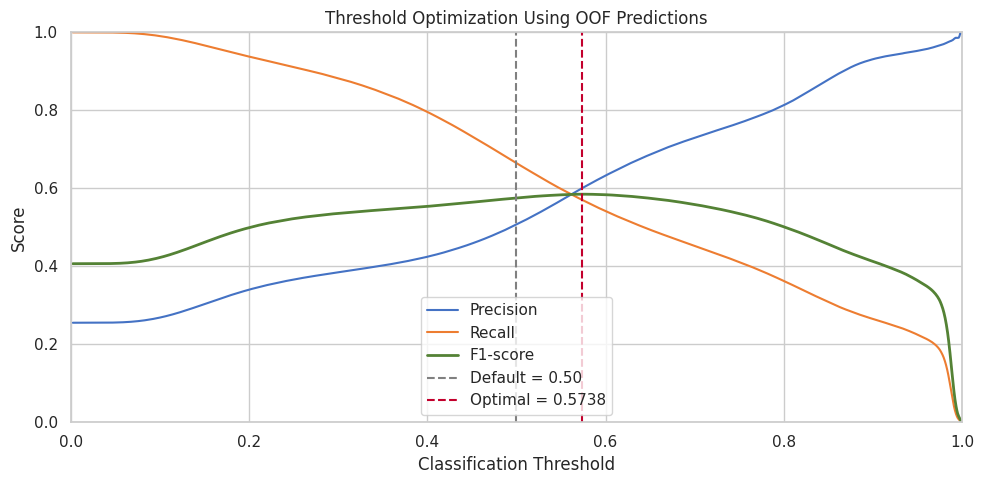


Fitting final preprocessing pipeline...
Final training matrix: (6308273, 88)
Preprocessing time: 13.98s
Final training time: 26.47s
Number of iterations: 60
Converged: True


threshold_type,Default,Optimized,Difference
threshold,5.000000e-01,5.738200e-01,0.07382
average_precision,6.827400e-01,6.827400e-01,0.00000
roc_auc,8.289100e-01,8.289100e-01,0.00000
accuracy,7.675300e-01,8.019100e-01,0.03438
precision,5.227500e-01,5.973100e-01,0.07456
recall,7.082900e-01,6.151200e-01,-0.09317
f1,6.015400e-01,6.060900e-01,0.00455
specificity,7.870400e-01,8.634300e-01,0.07638
brier_score,1.606500e-01,1.606500e-01,0.00000
true_negative,1.179539e+06,1.294017e+06,114478.00000


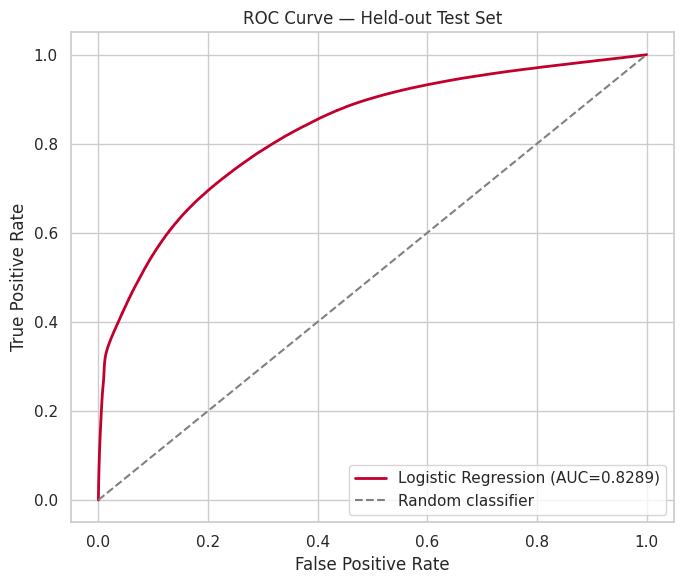

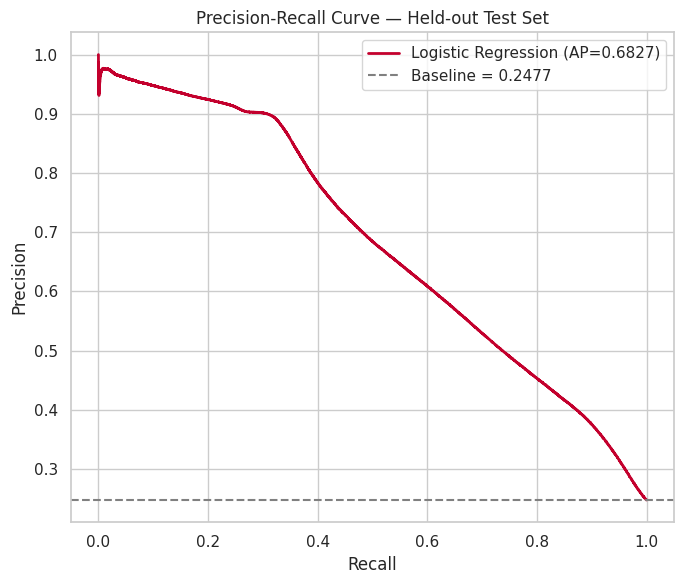

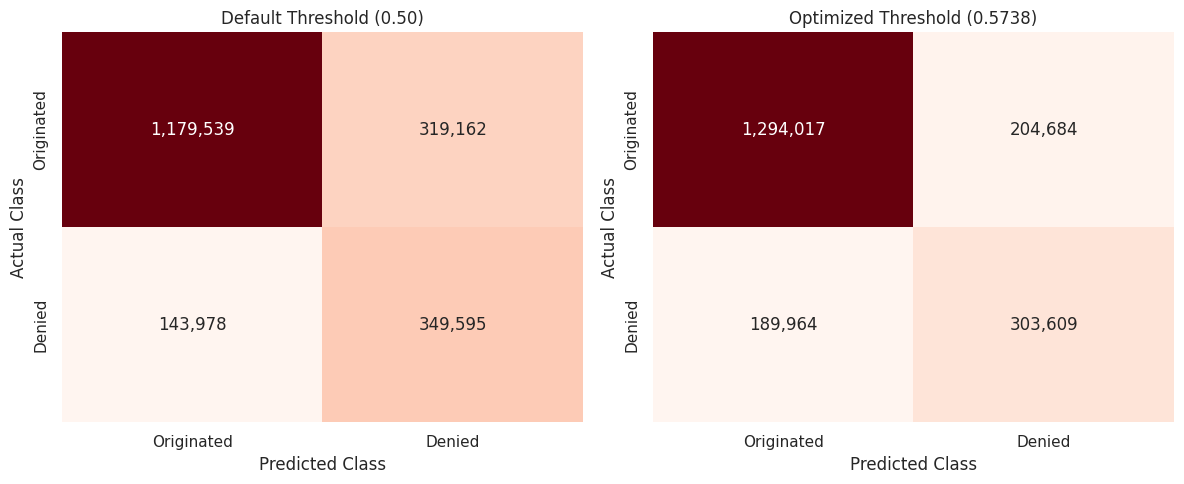


Final model saved successfully.
Test inference time: 2.98s
Test Average Precision: 0.68274
Test ROC-AUC: 0.82891

LR3 completed successfully.


In [4]:
# ============================================================
# LR3. FINAL MODEL TRAINING AND EVALUATION
# ============================================================

# ------------------------------------------------------------
# Step 1. Load selected configuration and OOF predictions
# ------------------------------------------------------------

with open(
    OUT + "lr_best_config.json", "r"
) as f:

    best_config = json.load(f)

oof_df = pd.read_parquet(
    OUT + "lr_oof_predictions.parquet"
)

assert np.array_equal(
    oof_df["row_idx"].to_numpy(),
    train_idx
)

assert np.array_equal(
    oof_df["y_true"].to_numpy(),
    y_train
)

best_oof_prob = oof_df["y_prob"].to_numpy()

# ------------------------------------------------------------
# Step 2. Optimize threshold using OOF predictions
# ------------------------------------------------------------

threshold_results = optimize_f1_threshold(
    y_train,
    best_oof_prob
)

OPTIMAL_THRESHOLD = threshold_results[
    "optimal_threshold"
]

threshold_config = {
    "model": "Logistic Regression",
    "config_id": best_config["config_id"],
    "default_threshold": DEFAULT_THRESHOLD,
    "optimal_threshold": OPTIMAL_THRESHOLD,
    "optimization_metric": "F1-score",
    "optimization_data": "Out-of-fold predictions",
    "oof_f1": threshold_results["optimal_f1"],
    "oof_precision": threshold_results["precision"],
    "oof_recall": threshold_results["recall"]
}

with open(
    OUT + "lr_threshold.json", "w"
) as f:

    json.dump(threshold_config, f, indent=4)

print("Optimal threshold configuration:")

display(
    pd.DataFrame(
        [threshold_config]
    ).round(5)
)

# Compare OOF threshold performance
oof_metrics = []

for threshold_type, threshold in [
    ("Default", DEFAULT_THRESHOLD),
    ("Optimized", OPTIMAL_THRESHOLD)
]:

    result = evaluate_predictions(
        y_train,
        best_oof_prob,
        threshold=threshold
    )

    result["threshold_type"] = threshold_type

    oof_metrics.append(result)

oof_metrics_df = pd.DataFrame(oof_metrics)

display(
    oof_metrics_df.round(5)
)

oof_metrics_df.to_csv(
    OUT + "lr_oof_metrics.csv",
    index=False
)

# ------------------------------------------------------------
# Step 3. Visualize OOF threshold optimization
# ------------------------------------------------------------

precision, recall, thresholds = (
    precision_recall_curve(
        y_train,
        best_oof_prob
    )
)

precision = precision[:-1]
recall = recall[:-1]

denominator = precision + recall

f1_values = np.divide(
    2 * precision * recall,
    denominator,
    out=np.zeros_like(denominator),
    where=denominator > 0
)

# Downsample plotting points only
# Threshold optimization uses all OOF predictions
plot_step = max(
    1,
    len(thresholds) // 2000
)

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    thresholds[::plot_step],
    precision[::plot_step],
    label="Precision",
    color="#4472C4"
)

ax.plot(
    thresholds[::plot_step],
    recall[::plot_step],
    label="Recall",
    color="#ED7D31"
)

ax.plot(
    thresholds[::plot_step],
    f1_values[::plot_step],
    label="F1-score",
    color="#548235",
    linewidth=2
)

ax.axvline(
    DEFAULT_THRESHOLD,
    linestyle="--",
    color="gray",
    label=f"Default = {DEFAULT_THRESHOLD:.2f}"
)

ax.axvline(
    OPTIMAL_THRESHOLD,
    linestyle="--",
    color="#C3002D",
    label=f"Optimal = {OPTIMAL_THRESHOLD:.4f}"
)

ax.set_xlabel("Classification Threshold")
ax.set_ylabel("Score")

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

ax.set_title(
    "Threshold Optimization Using OOF Predictions"
)

ax.legend()

plt.tight_layout()

plt.savefig(
    FIGURE_DIR + "LR3_threshold_optimization.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

del precision, recall, thresholds
del f1_values, denominator
del oof_df

gc.collect()

# ------------------------------------------------------------
# Step 4. Fit final preprocessing pipeline
# ------------------------------------------------------------

print("\nFitting final preprocessing pipeline...")

final_preprocessor = clone(lr_preprocessor)

preprocessing_start = time.perf_counter()

X_train_final = (
    final_preprocessor.fit_transform(X_train)
)

X_train_final = sparse.csr_matrix(
    X_train_final,
    dtype=np.float64
)

final_preprocessing_time = (
    time.perf_counter() - preprocessing_start
)

print(
    "Final training matrix:",
    X_train_final.shape
)

print(
    f"Preprocessing time: "
    f"{final_preprocessing_time:.2f}s"
)

# ------------------------------------------------------------
# Step 5. Train final Logistic Regression model
# ------------------------------------------------------------

final_model = build_lr_model(best_config)

final_train_start = time.perf_counter()

with warnings.catch_warnings(record=True) as caught:

    warnings.simplefilter(
        "always",
        ConvergenceWarning
    )

    final_model.fit(
        X_train_final,
        y_train
    )

final_training_time = (
    time.perf_counter() - final_train_start
)

final_converged = not any(
    issubclass(w.category, ConvergenceWarning)
    for w in caught
)

print(
    f"Final training time: "
    f"{final_training_time:.2f}s"
)

print(
    "Number of iterations:",
    int(final_model.n_iter_.max())
)

print("Converged:", final_converged)

assert final_converged, (
    "Final model did not converge. "
    "Review optimization settings."
)

# Construct fitted end-to-end pipeline
final_pipeline = Pipeline([
    ("preprocessor", final_preprocessor),
    ("classifier", final_model)
])

# Release training matrix
del X_train_final
gc.collect()

# ------------------------------------------------------------
# Step 6. Predict held-out test probabilities
# ------------------------------------------------------------

test_inference_start = time.perf_counter()

# Measure end-to-end prediction time
# Includes preprocessing and model inference
y_test_prob = final_pipeline.predict_proba(
    X_test
)[:, 1]

final_inference_time = (
    time.perf_counter() - test_inference_start
)

assert len(y_test_prob) == len(y_test)
assert np.isfinite(y_test_prob).all()

y_test_pred_default = (
    y_test_prob >= DEFAULT_THRESHOLD
).astype(np.int8)

y_test_pred_optimized = (
    y_test_prob >= OPTIMAL_THRESHOLD
).astype(np.int8)

# ------------------------------------------------------------
# Step 7. Evaluate held-out test performance
# ------------------------------------------------------------

test_results = []

for threshold_type, threshold in [
    ("Default", DEFAULT_THRESHOLD),
    ("Optimized", OPTIMAL_THRESHOLD)
]:

    metrics = evaluate_predictions(
        y_test,
        y_test_prob,
        threshold=threshold
    )

    metrics.update({
        "model": "Logistic Regression",
        "config_id": best_config["config_id"],
        "threshold_type": threshold_type,
        "test_observations": len(y_test),

        "preprocessing_time_sec": (
            final_preprocessing_time
        ),

        "training_time_sec": (
            final_training_time
        ),

        "total_fit_time_sec": (
            final_preprocessing_time
            + final_training_time
        ),

        "inference_time_sec": (
            final_inference_time
        ),

        "converged": final_converged
    })

    test_results.append(metrics)

test_metrics = pd.DataFrame(test_results)

METRIC_COLUMNS = [
    "threshold",
    "average_precision",
    "roc_auc",
    "accuracy",
    "precision",
    "recall",
    "f1",
    "specificity",
    "brier_score",
    "true_negative",
    "false_positive",
    "false_negative",
    "true_positive"
]

test_comparison = (
    test_metrics
    .set_index("threshold_type")[METRIC_COLUMNS]
    .T
)

test_comparison["Difference"] = (
    test_comparison["Optimized"]
    - test_comparison["Default"]
)

display(test_comparison.round(5))

test_metrics.to_csv(
    OUT + "lr_test_metrics.csv",
    index=False
)

test_comparison.to_csv(
    OUT + "lr_threshold_comparison.csv"
)

# ------------------------------------------------------------
# Step 8. Plot ROC curve
# ------------------------------------------------------------

fpr, tpr, _ = roc_curve(
    y_test,
    y_test_prob
)

test_auc = test_metrics.iloc[0]["roc_auc"]

fig, ax = plt.subplots(figsize=(7, 6))

ax.plot(
    fpr,
    tpr,
    color="#C3002D",
    linewidth=2,
    label=f"Logistic Regression (AUC={test_auc:.4f})"
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random classifier"
)

ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")

ax.set_title(
    "ROC Curve — Held-out Test Set"
)

ax.legend(loc="lower right")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR + "LR3_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# Step 9. Plot Precision-Recall curve
# ------------------------------------------------------------

test_precision, test_recall, _ = (
    precision_recall_curve(
        y_test,
        y_test_prob
    )
)

test_ap = test_metrics.iloc[0][
    "average_precision"
]

fig, ax = plt.subplots(figsize=(7, 6))

ax.plot(
    test_recall,
    test_precision,
    color="#C3002D",
    linewidth=2,
    label=f"Logistic Regression (AP={test_ap:.4f})"
)

ax.axhline(
    y_test.mean(),
    linestyle="--",
    color="gray",
    label=f"Baseline = {y_test.mean():.4f}"
)

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")

ax.set_title(
    "Precision-Recall Curve — Held-out Test Set"
)

ax.legend()

plt.tight_layout()

plt.savefig(
    FIGURE_DIR + "LR3_precision_recall_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# Step 10. Compare confusion matrices
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5)
)

for ax, predictions, title in [
    (
        axes[0],
        y_test_pred_default,
        f"Default Threshold ({DEFAULT_THRESHOLD:.2f})"
    ),
    (
        axes[1],
        y_test_pred_optimized,
        f"Optimized Threshold ({OPTIMAL_THRESHOLD:.4f})"
    )
]:

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt=",d",
        cmap="Reds",
        cbar=False,
        xticklabels=["Originated", "Denied"],
        yticklabels=["Originated", "Denied"],
        ax=ax
    )

    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")
    ax.set_title(title)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR + "LR3_confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# Step 11. Export held-out test predictions
# ------------------------------------------------------------

test_predictions = pd.DataFrame({
    "row_idx": test_idx,
    GROUP: groups_test.astype(str),
    "y_true": y_test,
    "y_prob": y_test_prob,
    "y_pred_default": y_test_pred_default,
    "y_pred_optimized": y_test_pred_optimized
})

assert test_predictions["row_idx"].is_unique

test_predictions.to_parquet(
    OUT + "lr_test_predictions.parquet",
    index=False
)

# ------------------------------------------------------------
# Step 12. Save fitted model pipeline
# ------------------------------------------------------------

joblib.dump(
    final_pipeline,
    OUT + "lr_final_pipeline.joblib"
)

print("\nFinal model saved successfully.")

print(
    f"Test inference time: "
    f"{final_inference_time:.2f}s"
)

print(
    f"Test Average Precision: "
    f"{test_ap:.5f}"
)

print(
    f"Test ROC-AUC: "
    f"{test_auc:.5f}"
)

print("\nLR3 completed successfully.")

## LR4. Model Interpretation and Artifact Export

The fitted Logistic Regression model is interpreted
through its estimated coefficients and corresponding
odds ratios.

Positive coefficients indicate a higher predicted
likelihood of loan denial, while negative coefficients
indicate a lower predicted likelihood, conditional
on the remaining model features.

Numerical coefficients represent changes associated
with a one-standard-deviation increase in the
preprocessed predictor.

Categorical coefficients are interpreted within
the full one-hot encoding parameterization.

The estimated associations do not establish
causal relationships.

All modeling artifacts, evaluation results,
predictions, and interpretation outputs are
consolidated for subsequent model comparison
and discussion in Step 18.

Original predictors: 12
Encoded predictors: 88
Model intercept: 0.4009796153777859


,rank,feature,feature_type,coefficient,odds_ratio,direction
0,1,dti_band_>60%,Categorical,3.36970,29.06978,Higher predicted denial odds
1,2,state_code_Not provided,Categorical,2.42432,11.29454,Higher predicted denial odds
2,3,loan_purpose_1,Categorical,-1.13466,0.32153,Lower predicted denial odds
3,4,construction_method_2,Categorical,1.01438,2.75765,Higher predicted denial odds
4,5,dti_band_36-43%,Categorical,-0.96203,0.38211,Lower predicted denial odds
5,6,dti_band_30-<36%,Categorical,-0.94000,0.39063,Lower predicted denial odds
6,7,dti_band_20-<30%,Categorical,-0.83112,0.43556,Lower predicted denial odds
7,8,missingindicator_property_value,Missing indicator,0.77681,2.17452,Higher predicted denial odds
8,9,dti_band_44-49%,Categorical,-0.70072,0.49623,Lower predicted denial odds
9,10,loan_purpose_4,Categorical,0.66947,1.95321,Higher predicted denial odds


,feature,feature_type,coefficient,odds_ratio,odds_change_pct
31,property_value,Log-transformed numerical,-0.28329,0.75330,-24.67006
46,log_loan_amount,Numerical,-0.14104,0.86845,-13.15477
56,loan_to_income,Log-transformed numerical,0.11705,1.12417,12.41728
61,combined_loan_to_value_ratio,Numerical,0.08673,1.09060,9.06011
82,log_income,Numerical,-0.00910,0.99094,-0.90615


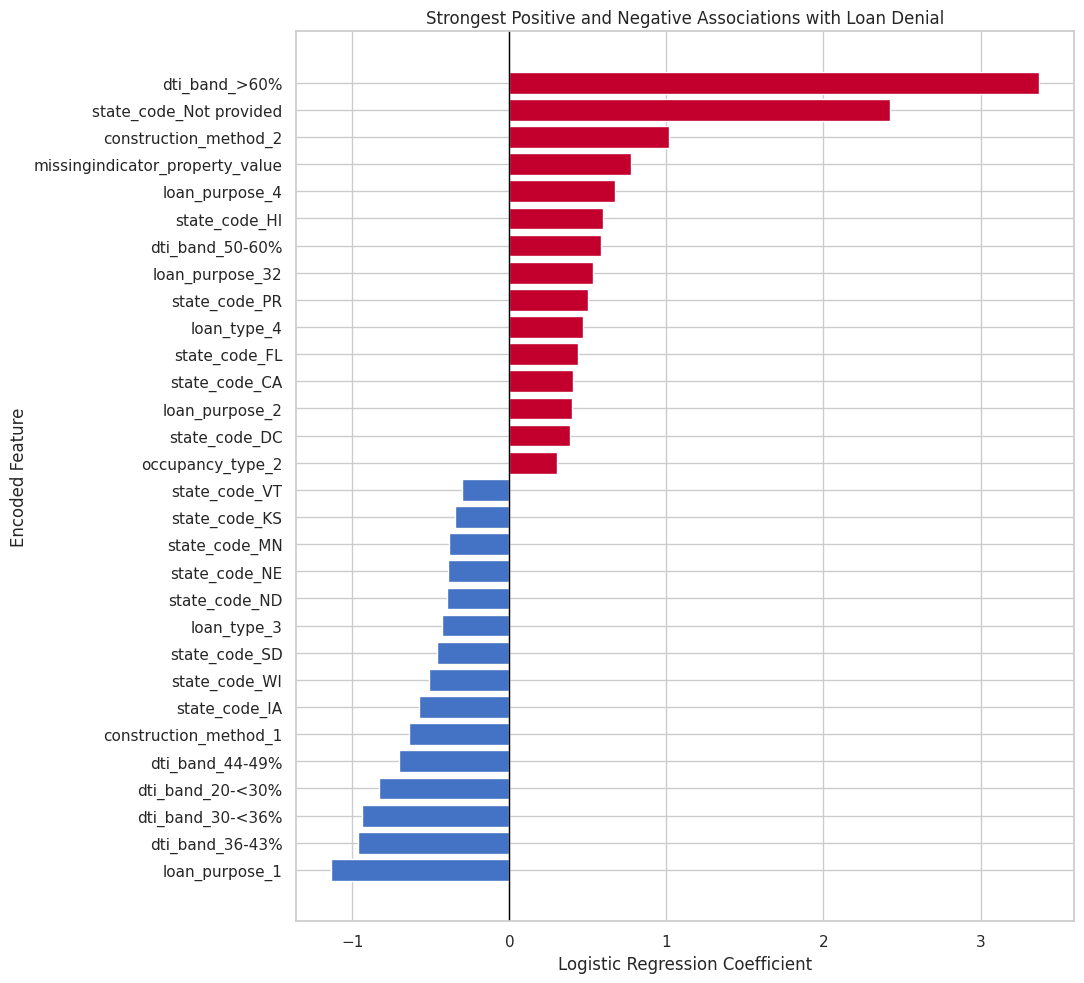

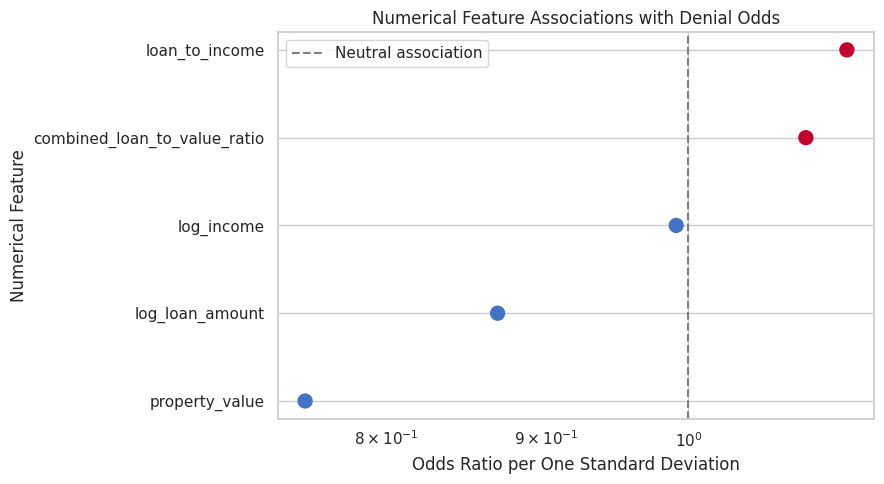

Prediction artifact integrity: PASS


,artifact,exists,size_mb,status
0,lr_partition_summary.csv,True,0.0002,PASS
1,lr_class_weight_summary.csv,True,0.0001,PASS
2,lr_cv_fold_results.csv,True,0.0137,PASS
3,lr_tuning_results.csv,True,0.0025,PASS
4,lr_cv_summary.csv,True,0.0005,PASS
5,lr_best_config.json,True,0.0005,PASS
6,lr_threshold.json,True,0.0003,PASS
7,lr_oof_predictions.parquet,True,76.4507,PASS
8,lr_oof_metrics.csv,True,0.0005,PASS
9,lr_test_predictions.parquet,True,24.5713,PASS


,metric,value
0,model,Logistic Regression
1,setup_version,1.0.0
2,original_predictors,12
3,encoded_predictors,88
4,training_applications,6308273
5,test_applications,1992274
6,cv_folds,5
7,selected_config,LR_02
8,penalty,l2
9,solver,lbfgs



STEP 16 — LOGISTIC REGRESSION COMPLETED
Selected configuration: LR_02
Selected regularization C: 0.01
Selected weighting strategy: Balanced
Test Average Precision: 0.68274
Test ROC-AUC: 0.82891
Optimized test F1: 0.60609
Artifact integrity: PASS
Output directory: /content/drive/MyDrive/hmda/rq4_logistic/

Ready for Step 18 — Model Comparison.


In [5]:
# ============================================================
# LR4. MODEL INTERPRETATION AND ARTIFACT EXPORT
# ============================================================

# ------------------------------------------------------------
# Step 1. Restore fitted model pipeline
# ------------------------------------------------------------

final_pipeline = joblib.load(
    OUT + "lr_final_pipeline.joblib"
)

final_preprocessor = (
    final_pipeline.named_steps["preprocessor"]
)

final_model = (
    final_pipeline.named_steps["classifier"]
)

with open(
    OUT + "lr_best_config.json", "r"
) as f:

    best_config = json.load(f)

with open(
    OUT + "lr_threshold.json", "r"
) as f:

    threshold_config = json.load(f)

# ------------------------------------------------------------
# Step 2. Extract transformed feature names
# ------------------------------------------------------------

transformed_features = (
    final_preprocessor.get_feature_names_out()
)

coefficients = final_model.coef_.ravel()

assert len(transformed_features) == len(
    coefficients
)

assert np.array_equal(
    final_model.classes_,
    np.array([0, 1])
)

# ------------------------------------------------------------
# Step 3. Construct coefficient interpretation table
# ------------------------------------------------------------

coefficient_df = pd.DataFrame({
    "transformed_feature": transformed_features,
    "coefficient": coefficients
})

coefficient_df["feature"] = (
    coefficient_df["transformed_feature"]
    .str.split("__", n=1)
    .str[-1]
)

coefficient_df["feature_type"] = (
    coefficient_df["transformed_feature"]
    .str.split("__", n=1)
    .str[0]
    .map({
        "numeric_identity": "Numerical",
        "numeric_log": "Log-transformed numerical",
        "categorical": "Categorical",
        "missing_indicator": "Missing indicator"
    })
)

coefficient_df["odds_ratio"] = np.exp(
    coefficient_df["coefficient"]
)

coefficient_df["absolute_coefficient"] = (
    coefficient_df["coefficient"].abs()
)

coefficient_df["direction"] = np.select(
    [
        coefficient_df["coefficient"] > 0,
        coefficient_df["coefficient"] < 0
    ],
    [
        "Higher predicted denial odds",
        "Lower predicted denial odds"
    ],
    default="Neutral"
)

coefficient_df["odds_change_pct"] = (
    coefficient_df["odds_ratio"] - 1
) * 100

coefficient_df = (
    coefficient_df
    .sort_values(
        "absolute_coefficient",
        ascending=False
    )
    .reset_index(drop=True)
)

coefficient_df.insert(
    0,
    "rank",
    np.arange(1, len(coefficient_df) + 1)
)

coefficient_df.to_csv(
    OUT + "lr_coefficients.csv",
    index=False
)

print("Original predictors:", len(FEATURES))

print(
    "Encoded predictors:",
    len(transformed_features)
)

print(
    "Model intercept:",
    float(final_model.intercept_[0])
)

display(
    coefficient_df[
        [
            "rank",
            "feature",
            "feature_type",
            "coefficient",
            "odds_ratio",
            "direction"
        ]
    ].head(20).round(5)
)

# ------------------------------------------------------------
# Step 4. Extract numerical feature interpretation
# ------------------------------------------------------------

numeric_coefficients = coefficient_df[
    coefficient_df["feature_type"].isin([
        "Numerical",
        "Log-transformed numerical"
    ])
].copy()

numeric_coefficients["interpretation_unit"] = (
    "One standard deviation in transformed predictor"
)

numeric_coefficients.to_csv(
    OUT + "lr_numeric_coefficients.csv",
    index=False
)

display(
    numeric_coefficients[
        [
            "feature",
            "feature_type",
            "coefficient",
            "odds_ratio",
            "odds_change_pct"
        ]
    ].round(5)
)

# ------------------------------------------------------------
# Step 5. Extract strongest positive and negative coefficients
# ------------------------------------------------------------

TOP_N = 15

top_positive = (
    coefficient_df[
        coefficient_df["coefficient"] > 0
    ]
    .nlargest(TOP_N, "coefficient")
    .copy()
)

top_negative = (
    coefficient_df[
        coefficient_df["coefficient"] < 0
    ]
    .nsmallest(TOP_N, "coefficient")
    .copy()
)

top_positive.to_csv(
    OUT + "lr_top_positive_coefficients.csv",
    index=False
)

top_negative.to_csv(
    OUT + "lr_top_negative_coefficients.csv",
    index=False
)

# ------------------------------------------------------------
# Step 6. Visualize coefficient directions
# ------------------------------------------------------------

plot_coefficients = (
    pd.concat(
        [top_positive, top_negative],
        ignore_index=True
    )
    .sort_values("coefficient")
)

fig, ax = plt.subplots(figsize=(11, 10))

colors = np.where(
    plot_coefficients["coefficient"] > 0,
    "#C3002D",
    "#4472C4"
)

ax.barh(
    plot_coefficients["feature"],
    plot_coefficients["coefficient"],
    color=colors
)

ax.axvline(
    0,
    color="black",
    linewidth=1
)

ax.set_xlabel(
    "Logistic Regression Coefficient"
)

ax.set_ylabel("Encoded Feature")

ax.set_title(
    "Strongest Positive and Negative Associations "
    "with Loan Denial"
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR + "LR4_top_coefficients.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# Step 7. Visualize numerical odds ratios
# ------------------------------------------------------------

numeric_plot = numeric_coefficients.sort_values(
    "odds_ratio"
)

fig, ax = plt.subplots(figsize=(9, 5))

colors = np.where(
    numeric_plot["odds_ratio"] > 1,
    "#C3002D",
    "#4472C4"
)

ax.scatter(
    numeric_plot["odds_ratio"],
    numeric_plot["feature"],
    c=colors,
    s=100
)

ax.axvline(
    1,
    linestyle="--",
    color="gray",
    label="Neutral association"
)

ax.set_xscale("log")

ax.set_xlabel(
    "Odds Ratio per One Standard Deviation"
)

ax.set_ylabel("Numerical Feature")

ax.set_title(
    "Numerical Feature Associations with Denial Odds"
)

ax.legend()

plt.tight_layout()

plt.savefig(
    FIGURE_DIR + "LR4_numeric_odds_ratios.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# Step 8. Build final model performance summary
# ------------------------------------------------------------

test_metrics = pd.read_csv(
    OUT + "lr_test_metrics.csv"
)

default_metrics = (
    test_metrics[
        test_metrics["threshold_type"] == "Default"
    ]
    .iloc[0]
)

optimized_metrics = (
    test_metrics[
        test_metrics["threshold_type"] == "Optimized"
    ]
    .iloc[0]
)

model_summary = {
    "model": "Logistic Regression",

    "setup_version": master_config["setup_version"],

    "original_predictors": len(FEATURES),

    "encoded_predictors": len(
        transformed_features
    ),

    "training_applications": len(y_train),

    "test_applications": len(y_test),

    "cv_folds": N_SPLITS,

    "selected_config": best_config["config_id"],

    "penalty": best_config["penalty"],

    "solver": best_config["solver"],

    "C": best_config["C"],

    "weight_strategy": (
        best_config["weight_strategy"]
    ),

    "mean_cv_average_precision": (
        best_config["mean_cv_ap"]
    ),

    "std_cv_average_precision": (
        best_config["std_cv_ap"]
    ),

    "default_threshold": (
        threshold_config["default_threshold"]
    ),

    "optimized_threshold": (
        threshold_config["optimal_threshold"]
    ),

    "test_average_precision": float(
        optimized_metrics["average_precision"]
    ),

    "test_roc_auc": float(
        optimized_metrics["roc_auc"]
    ),

    "test_brier_score": float(
        optimized_metrics["brier_score"]
    ),

    "test_accuracy": float(
        optimized_metrics["accuracy"]
    ),

    "test_precision": float(
        optimized_metrics["precision"]
    ),

    "test_recall": float(
        optimized_metrics["recall"]
    ),

    "test_specificity": float(
        optimized_metrics["specificity"]
    ),

    "test_f1_default": float(
        default_metrics["f1"]
    ),

    "test_f1_optimized": float(
        optimized_metrics["f1"]
    ),

    "preprocessing_time_sec": float(
        optimized_metrics["preprocessing_time_sec"]
    ),

    "training_time_sec": float(
        optimized_metrics["training_time_sec"]
    ),

    "total_fit_time_sec": float(
        optimized_metrics["total_fit_time_sec"]
    ),

    "inference_time_sec": float(
        optimized_metrics["inference_time_sec"]
    ),

    "model_intercept": float(
        final_model.intercept_[0]
    ),

    "model_iterations": int(
        final_model.n_iter_.max()
    ),

    "converged": bool(final_converged)
}

with open(
    OUT + "lr_model_summary.json", "w"
) as f:

    json.dump(
        model_summary,
        f,
        indent=4
    )

pd.DataFrame(
    [model_summary]
).to_csv(
    OUT + "lr_model_summary.csv",
    index=False
)

# ------------------------------------------------------------
# Step 9. Validate exported predictions
# ------------------------------------------------------------

saved_test_predictions = pd.read_parquet(
    OUT + "lr_test_predictions.parquet"
)

saved_oof_predictions = pd.read_parquet(
    OUT + "lr_oof_predictions.parquet"
)

assert len(saved_test_predictions) == len(y_test)
assert len(saved_oof_predictions) == len(y_train)

assert saved_test_predictions["row_idx"].is_unique
assert saved_oof_predictions["row_idx"].is_unique

assert np.array_equal(
    saved_test_predictions["row_idx"].to_numpy(),
    test_idx
)

assert np.array_equal(
    saved_oof_predictions["row_idx"].to_numpy(),
    train_idx
)

assert np.array_equal(
    saved_test_predictions["y_true"].to_numpy(),
    y_test
)

assert np.array_equal(
    saved_oof_predictions["y_true"].to_numpy(),
    y_train
)

assert not set(
    saved_test_predictions[GROUP]
).intersection(
    set(saved_oof_predictions[GROUP])
)

print("Prediction artifact integrity: PASS")

# ------------------------------------------------------------
# Step 10. Validate required modeling artifacts
# ------------------------------------------------------------

REQUIRED_ARTIFACTS = [
    "lr_partition_summary.csv",
    "lr_class_weight_summary.csv",
    "lr_cv_fold_results.csv",
    "lr_tuning_results.csv",
    "lr_cv_summary.csv",
    "lr_best_config.json",
    "lr_threshold.json",
    "lr_oof_predictions.parquet",
    "lr_oof_metrics.csv",
    "lr_test_predictions.parquet",
    "lr_test_metrics.csv",
    "lr_threshold_comparison.csv",
    "lr_coefficients.csv",
    "lr_numeric_coefficients.csv",
    "lr_top_positive_coefficients.csv",
    "lr_top_negative_coefficients.csv",
    "lr_final_pipeline.joblib",
    "lr_model_summary.json",
    "lr_model_summary.csv"
]

artifact_results = []

for filename in REQUIRED_ARTIFACTS:

    path = os.path.join(OUT, filename)

    exists = os.path.exists(path)

    artifact_results.append({
        "artifact": filename,
        "exists": exists,
        "size_mb": (
            os.path.getsize(path) / 1024**2
            if exists
            else 0
        ),
        "status": (
            "PASS"
            if exists
            else "FAIL"
        )
    })

artifact_summary = pd.DataFrame(
    artifact_results
)

assert artifact_summary["exists"].all()

artifact_summary.to_csv(
    OUT + "lr_artifact_manifest.csv",
    index=False
)

display(
    artifact_summary.round(4)
)

# ------------------------------------------------------------
# Step 11. Display final modeling summary
# ------------------------------------------------------------

summary_display = pd.DataFrame({
    "metric": list(model_summary.keys()),
    "value": list(model_summary.values())
})

display(summary_display)

del saved_test_predictions
del saved_oof_predictions

gc.collect()

print("\n" + "=" * 65)

print("STEP 16 — LOGISTIC REGRESSION COMPLETED")

print("=" * 65)

print(
    "Selected configuration:",
    best_config["config_id"]
)

print(
    "Selected regularization C:",
    best_config["C"]
)

print(
    "Selected weighting strategy:",
    best_config["weight_strategy"]
)

print(
    "Test Average Precision:",
    round(model_summary["test_average_precision"], 5)
)

print(
    "Test ROC-AUC:",
    round(model_summary["test_roc_auc"], 5)
)

print(
    "Optimized test F1:",
    round(model_summary["test_f1_optimized"], 5)
)

print("Artifact integrity: PASS")
print("Output directory:", OUT)

print("\nReady for Step 18 — Model Comparison.")